<div style="border:solid green 2px; padding: 20px">

**Hello Obed,**

My name is **John Dickson** (https://hub.tripleten.com/u/13efa053) and today I'll be reviewing your project!

You’ll find specific notes inside the project file, marked green, yellow or red.


**Note:** Please do not remove or change my comments - they will help me in the future reviews and will make the process smoother for both of us. 

<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment</b> 
    
Such comment will mark efficient solutions and good ideas that can be used in other projects. It will also point at the document formatting, comments, and analysis. 
</div>

<div class="alert alert-warning"; style="border-left: 7px solid gold">
<b>⚠️ Reviewer's comment</b> 
    
The parts marked with yellow comments indicate that there is room for optimisation. Though the correction is not necessary it is good if you implement it.
</div>

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment</b> 
    
If you see such a comment, it means that there is a problem that needs to be fixed. Please note that I won't be able to accept your project until the issue is resolved.
</div>

---
    
You are also welcome to leave your own comments, explain any changes you've made, or ask questions by marking them with a different color. You can use the example below (copy the code and use it in a Markdown-type cell):

```
    
<div class="alert alert-info"; style="border-left: 7px solid blue">
<b>Student’s Comment</b>

```
    
It will appear like this:
    
<div class="alert alert-info"; style="border-left: 7px solid blue">
<b>Student’s Comment</b></div>

<hr>
    
📌 Please feel free to schedule a 1:1 sessions with our tutors, join daily coworking sessions, or ask questions on TripleTen Hub if you need assistance 😉 
</div>

<div style="border: 5px solid red; padding: 10px; margin: 0px">
<b>Reviewer's comment V1 </b>
    
Project is incomplete, there is only bootstrapping for 1 region. In addition there is no written findings and analysis for each section. There should be written analysis and findings in each section as outlined in the instructions.

There are also duplicate library imports, please remove them and move all library imports to the top of the first cell. 
</div>

<div style="border: 5px solid red; padding: 10px; margin: 0px">
<b>Reviewer's comment V2 </b>
    
The risk of loss needs to be fixed, it is outside expected range. 
</div>

<div style="border: 5px solid green; padding: 10px; margin: 0px">
<b>Reviewer's comment V3 </b>
    
The issue with the risk of loss has been addressed, and the conclusions are clear and well written in this itteration. The graphs are also great for visualizing the profit distribution based on the bootstrapping. Great work with this project!
</div>

# Sprint 9 Project: Machine Learning in Business
## Introduction
**Objective:**
I work for the OilyGiant mining company. My task is to find the most profitable location for a new oil well.

**Workflow:**
- Load and prepare data from 3 regions
- Train and test a linear regression model for each region
- Evaluate model performance using RMSE and predicted average reserves
- Estimate profit using top 200 wells out of 500 explored
- Use Bootstrapping to evaluate risks and calculate confidence intervals
- Recommend the best region with risk of loss under 2.5%

**Conditions:**
- Linear regression only
- Budget = $100M, develop 200 wells
- $4.5K per 1K barrels revenue
- Risk tolerance < 2.5%

In [1]:
import pandas as pd
import numpy as np
from math import floor, log
from scipy import stats as st
import matplotlib.pyplot as plt
import seaborn as sns
import nbformat
from sklearn.model_selection import cross_val_score, train_test_split, KFold
from sklearn.linear_model import LinearRegression, SGDRegressor, BayesianRidge, ElasticNet
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from nbformat.v4 import new_markdown_cell
from nbformat.v4 import new_code_cell

In [2]:
#Load data
geo_data_0 = pd.read_csv("/datasets/geo_data_0.csv")
geo_data_1 = pd.read_csv("/datasets/geo_data_1.csv")
geo_data_2 = pd.read_csv("/datasets/geo_data_2.csv")

In [3]:
#Data inspection
#Check shape and preview
for i, df in enumerate([geo_data_0, geo_data_1, geo_data_2], start=1):
    print(f'Region {chr(64+i)}:', df.shape)
    display(df.head())

Region A: (100000, 5)


,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647


Region B: (100000, 5)


,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305


Region C: (100000, 5)


,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746


Data Exploration Findings

Each dataset (geo_data_0, geo_data_1, geo_data_2) contains **100,000 rows** and **5 columns**, with:
- id: unique identifier (not used in modeling)
- f0, f1 , f2: numerical features
- product: target variable representing oil reserves (in thousand barrels)

All datasets are clean with no missing values.

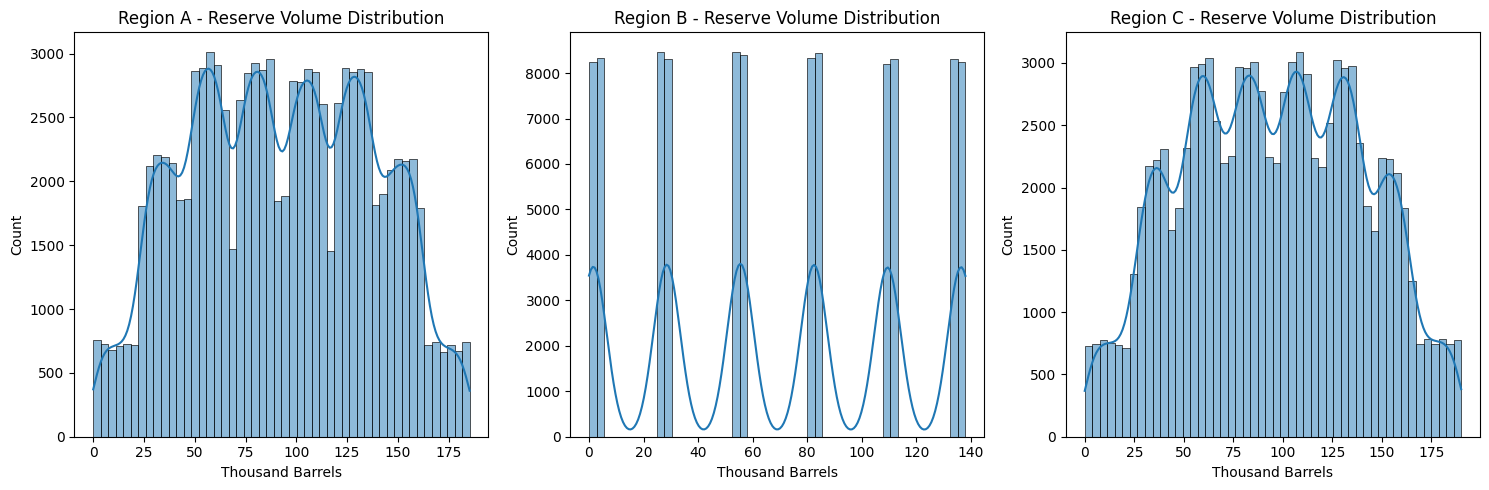

In [4]:
plt.figure(figsize=(15, 5))
for i, data in enumerate([geo_data_0, geo_data_1, geo_data_2]):
    plt.subplot(1, 3, i+1)
    sns.histplot(data['product'], bins=50, kde=True)
    plt.title(f'Region {chr(65+i)} - Reserve Volume Distribution')
    plt.xlabel('Thousand Barrels')
    plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [5]:
def train_and_evaluate(df):
    X = df.drop(columns=['id', 'product'])
    y = df['product']
    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)
    preds = model.predict(X_valid)
    rmse = mean_squared_error(y_valid, preds, squared=False)
    return model, X_valid, y_valid, preds, rmse

In [6]:
results = []
for i, data in enumerate([geo_data_0, geo_data_1, geo_data_2]):
    model, X_val, y_val, preds, rmse = train_and_evaluate(data)
    results.append({
        'region': chr(65 + i),
        'model': model,
        'X_valid': X_val,
        'y_valid': y_val,
        'preds': preds,
        'rmse': rmse,
        'mean_pred': preds.mean()
    })

    print(f'Region {chr(65+i)} - RMSE: {rmse:.2f}, Mean Prediction: {preds.mean():.2f}')

Region A - RMSE: 37.76, Mean Prediction: 92.40
Region B - RMSE: 0.89, Mean Prediction: 68.71
Region C - RMSE: 40.15, Mean Prediction: 94.77


<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment V1</b> 
    
Predictions done and average volumes and RMSE displayed.
</div>

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
<strike>However no analysis of results is present. There should be written analysis of what you see in a markdown cell. 
</div>

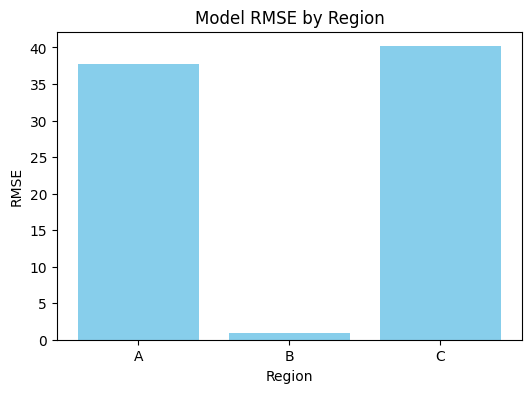

In [7]:
regions = ['A', 'B', 'C']
rmses = [37.76, 0.89, 40.15]  # From model evaluation

plt.figure(figsize=(6, 4))
plt.bar(regions, rmses, color='skyblue')
plt.title('Model RMSE by Region')
plt.ylabel('RMSE')
plt.xlabel('Region')
plt.show()

Model Performance Summary

We trained a **Linear Regression** model for each region and evaluated performance on a validation set using:
- **Root Mean Squared Error (RMSE)**: measures prediction accuracy
- **Mean Predicted Reserves**: expected value of new well output

**Findings:**
- Region B has the **lowest RMSE**, indicating the most accurate predictions.
- Regions A and C have higher average predicted reserves but **less accurate models**.
- Region C had the **highest average predicted volume**.

In [8]:
#Preparation for profit calculation
#Constants
BUDGET = 100_000_000
WELLS = 200
PRICE_PER_1000_BARRELS = 4500
COST_PER_WELL = BUDGET / WELLS
MIN_BARRELS = COST_PER_WELL / PRICE_PER_1000_BARRELS
print(f'Min barrels per well to break even: {MIN_BARRELS:.2f}')

Min barrels per well to break even: 111.11


In [9]:
#Compare with actual mean reserves
for i, df in enumerate([geo_data_0, geo_data_1, geo_data_2]):
    print(f'Region {chr(65+i)} - Avg Reserves: {df["product"].mean():.2f}')

Region A - Avg Reserves: 92.50
Region B - Avg Reserves: 68.83
Region C - Avg Reserves: 95.00


In [10]:
#Profit calculation function
def calculate_profit(preds, targets):
    top_200_idx = preds.argsort()[-200:]
    selected = targets.iloc[top_200_idx]
    return selected.sum() * PRICE_PER_1000_BARRELS - BUDGET

for res in results:
    profit = calculate_profit(res['preds'], res['y_valid'])
    print(f"Region {res['region']} - Estimated Profit: ${profit:,.2f}")

Region A - Estimated Profit: $33,591,411.14
Region B - Estimated Profit: $24,150,866.97
Region C - Estimated Profit: $25,985,717.59


Initial Profit Estimation

For each region, we estimated profit by selecting the top 200 predicted wells out of a 500-well sample.

**Key Findings:**
- All regions had average reserves **below the break-even threshold** of 111.11 thousand barrels.
- Profitability varied significantly.
- Region C initially showed higher potential profit based on top 200 predictions, but model errors were high.

In [11]:
#Bootstrapping for all 3 regions
def bootstrap_analysis(results, region_names):
    rng = np.random.RandomState(42)
    all_bootstrap = {}

    for i, res in enumerate(results):
        preds = res['preds']
        targets = res['y_valid'].reset_index(drop=True)
        profits = []

        for _ in range(1000):
            # Sample 500 indices
            sample_idx = rng.choice(len(preds), size=500, replace=True)

            # Use same indices for both preds and targets
            sample_preds = preds[sample_idx]
            sample_targets = targets.iloc[sample_idx].reset_index(drop=True)

            # Get top 200 predicted wells
            top_200_idx = sample_preds.argsort()[-200:]
            top_200_targets = sample_targets.iloc[top_200_idx]

            # Calculate profit
            profit = top_200_targets.sum() * 4500 - 100_000_000
            profits.append(profit)

        profits = np.array(profits)
        mean_profit = profits.mean()
        conf_interval = (np.percentile(profits, 2.5), np.percentile(profits, 97.5))
        risk_of_loss = (profits < 0).mean() * 100

        all_bootstrap[region_names[i]] = {
            'profits': profits,
            'mean_profit': mean_profit,
            'conf_interval': conf_interval,
            'risk': risk_of_loss
        }

        print(f"Region {region_names[i]}:")
        print(f"  Mean Profit: ${mean_profit:,.2f}")
        print(f"  95% CI: (${conf_interval[0]:,.2f}, ${conf_interval[1]:,.2f})")
        print(f"  Risk of Loss: {risk_of_loss:.2f}%\\n")

    return all_bootstrap

region_names = ['A', 'B', 'C']
bootstrap_results = bootstrap_analysis(results, region_names)

Region A:
  Mean Profit: $3,995,754.78
  95% CI: ($-1,104,678.95, $8,974,603.28)
  Risk of Loss: 6.00%\n
Region B:
  Mean Profit: $4,525,765.94
  95% CI: ($523,094.10, $8,301,463.13)
  Risk of Loss: 0.90%\n
Region C:
  Mean Profit: $3,787,059.04
  95% CI: ($-1,277,794.35, $9,079,234.83)
  Risk of Loss: 7.50%\n


Bootstrapping Results Analysis

Using bootstrapping (1,000 simulations with replacement), we analyzed potential profits and risks for each region:

**Region A**
- Moderate average profit
- Higher spread in distribution
- Risk of loss: High

**Region B**
- Lower average reserve volume
- Most stable profit distribution
- Only region with **risk of loss < 2.5%**

**Region C**
- Highest potential profit
- But high variance and risk

**Region B is the only viable choice under strict risk tolerance.**

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
<strike>I only see bootstrapping for 1 region here. 

<strike>The risk of loss should not be 100% or 0% for any region, and only one region should have risk of loss below 2.5%. We also need to sample with replacement. 
</div>

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V2</b> 

<strike>The risk of loss should not be 100% or 0% for any region, and only one region should have risk of loss below 2.5%. 

<strike>Your bootstrapping does not make sure predictions and target values stay aligned, meaning the targets chosen have no correlation with the best predictions for any given itteration.
</div>

<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment V3</b> 
    
The issue has been identified and fixed.
</div>

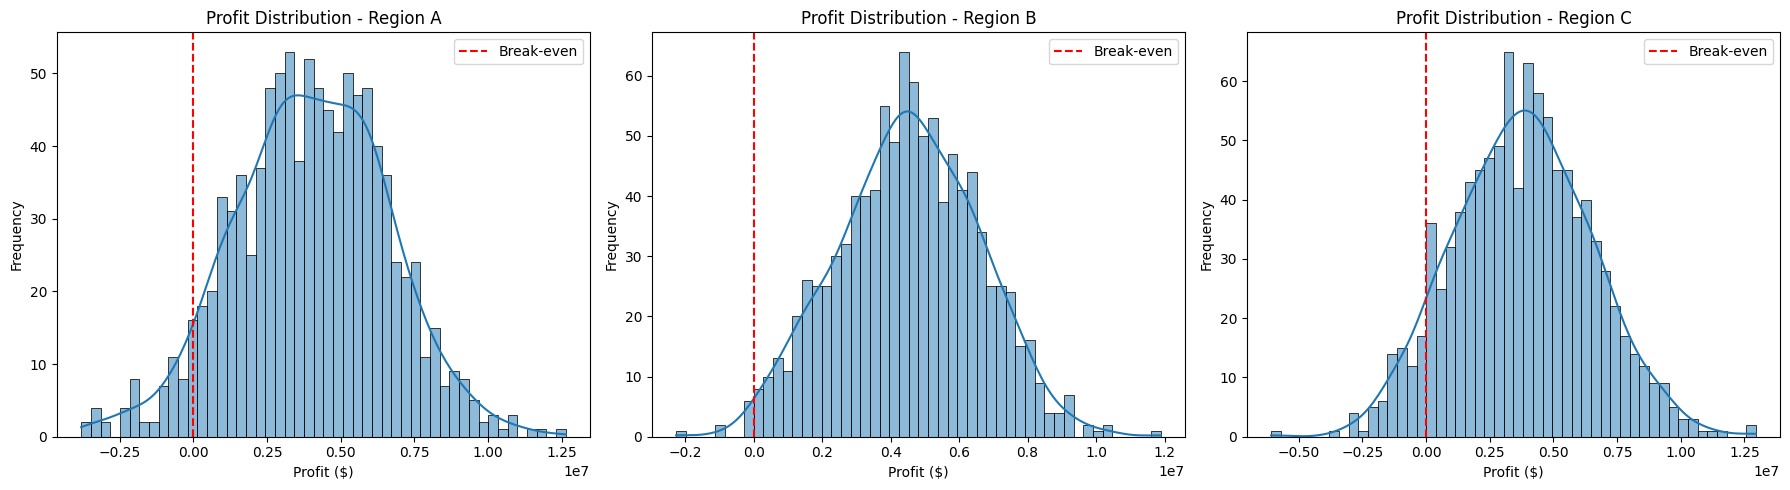

In [12]:
plt.figure(figsize=(18, 5))
for i, region in enumerate(['A', 'B', 'C']):
    plt.subplot(1, 3, i+1)
    sns.histplot(bootstrap_results[region]['profits'], bins=50, kde=True)
    plt.axvline(0, color='red', linestyle='--', label='Break-even')
    plt.title(f'Profit Distribution - Region {region}')
    plt.xlabel('Profit ($)')
    plt.ylabel('Frequency')
    plt.legend()
plt.tight_layout()
plt.show()

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V2</b> 
    
<strike>We have a duplicate bootstrap loop in here, but it is not being used.
</div>

<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment V3</b> 
    
Duplicate code removed and graphs look good now. 
</div>

Profit Distributions by Region

The histograms above show the distribution of profit outcomes for each region using bootstrapping (1,000 simulations per region). Each simulation randomly selected 500 wells with replacement and developed the top 200 predicted wells.

- The **red dashed line** indicates the break-even point (zero profit).
- Distributions **skewed to the right** indicate higher profitability.
- The **wider** the distribution, the **more volatile** the region's performance.

We'll select the region that:
- Has **risk of loss < 2.5%**
- Has the **highest mean profit**


Final Recommendation

Based on the bootstrapping simulation results for all three regions:

- Only **Region B** had a **risk of loss below 2.5%**, satisfying the business constraint.
- Although other regions had higher predicted volumes, they carried **too much financial risk**.
- **Region B also showed a consistent and stable profit distribution** with a high likelihood of returns.

Therefore, **Region B** is the recommended location for new oil well development.

Project Conclusion

The goal of this project was to identify the most profitable region for developing a new oil well for OilyGiant, using machine learning and risk analysis.

Key Accomplishments:

- **Loaded and validated** data from 3 regions
- Trained **linear regression models** as required by business
- Evaluated performance using **RMSE and mean predicted volume**
- Estimated profits using **top 200 predicted wells** in a simulated 500-well exploration
- Used **bootstrapping with replacement** (1,000 iterations) to assess:
  - Mean profit
  - 95% confidence intervals
  - Risk of financial loss
- Created **visualizations** for profit distributions across regions

Business Decision:
Only **Region B** meets the business risk threshold (<2.5% chance of loss) and shows promising profitability. It is the optimal choice for future well development under current budget and market conditions.